# 00 学習済みTTConvの事後rank配分：三つの選択基準

この Notebook が扱う問いは次である。

> 同じ候補集合・費用制約の下で、重み情報、入力分布、ラベル情報のどこまで使うと、検証性能を保つTTConv rank配分を選べるか。また、その傾向はFashion-MNIST TT-MLPのNotebook 10と共通するか。

対象は、既存の学習済み `conv2` TTConvを、共通のcheckpointから独立に切り詰めた候補である。Dense weightから候補ごとにTT-SVDし直す実験ではない。fine-tuningも、CNN用のDMRG-like学習も行わない。

三つの選択スコアは同じ候補集合、同じcalibration subset、同じ費用制約を使う。

1. Weight-aware：元TTConvの実効weightとの相対Frobenius誤差。
2. Activation-aware：同じ対象層入力feature mapに対する、`conv2` のpre-activation出力の相対L2誤差。
3. Task-aware：calibrationデータ上の平均cross-entropyの増加。

選択はcalibrationだけで確定して保存する。その後にだけ、選択へ使わないrank-selection validationで全候補を評価し、候補集合内のoracleとselection regretを診断する。


## 元checkpointとデータの役割

元モデルは、CNN fine-tuning系列04の `rank_24_selected.pt` である。04の保存済み設定では、rank 24はPareto kneeではなく、03の圧縮直後にdense accuracyへほぼ戻った accuracy-recovery reference として学習前から固定されている。checkpoint内の選択規則は `finetuning_monitor_loss`、選択epochは9である。今回の三基準の結果を見て選んではいない。

実物は次のとおりである。

- 対象層は `conv2`。入力32、出力64、kernel 3、stride 1、padding 1。pool1のあとなので入力空間は14×14、出力空間も14×14である。
- tensorizationは04と同じ `out_modes = (4, 4, 4)`、`in_modes = (6, 6, 8)`。`4*4*4 = 64`、`6*6*8 = 288 = 32*3*3`。
- actual rankは `(1, 24, 24, 1)`。内部bondは2本で、どちらも24ある。
- main実行時に、全16候補を共通の元coreから独立に生成し、要求rankとactual rankの一致、および候補rank列の重複がないことを検証する。

データの役割は04のsplit indexをそのまま使う。

- 学習50,000件：04がTT coreの更新に使った。calibration subsetはこの中だけから取る。未使用データではない。
- finetuning monitor 5,000件：04がcheckpoint選択に使った。このNotebookのcalibrationにも候補選択にも使わない。
- rank-selection validation 5,000件：02・03・04で診断に使われた開発用評価である。独立した最終試験とは呼ばない。三基準の選択が保存されたあと、全候補の比較とoracle診断にだけ使う。
- test 10,000件：長さの確認以外では走査しない。選択、設計、最終表に使わない。

calibrationは、学習50,000件に対する `make_torch_generator(10)` の `randperm` から先頭5,000件である。件数とseedはNotebook 10で実験前に固定されていた規則を、このCNNの学習indexへ移したものであり、今回のスコアを見て決めていない。


## 候補、切り詰め、費用

内部bondの候補は、元rankが許容する既存のrank集合から取る。

$$
r_1,r_2\in\{12,16,20,24\}
$$

16候補である。各候補は元checkpointのcoreから独立に作る。前の候補をさらに切り詰めることはしない。

主解析の切り詰めは、bond 1のあとにbond 2、SVDの `direction="right"`、dtypeはfloat32、deviceはCPUで固定する。bond番号はrank列 `(1, r_1, r_2, 1)` の位置である。pair indexはbond番号から1を引いた値で、既存の `truncate_tt_matrix_bonds` へ渡す。ノルムの再正規化はしない。

元rank `(1, 24, 24, 1)` を同じ手順で作り直すcontrolを、候補評価の前に行う。実効weight、少数の固定入力に対する `conv2` 出力とlogits、`conv2` 以外のparameter、bias、元オブジェクトの不変、通常forwardがdense kernelを持たないことを確認する。失敗したら候補評価へ進まず停止する。

主費用は、`tt_conv2d_forward` の直接縮約に対応する `tt_conv2d_direct_contraction_macs` である。出力位置数は14×14で、rankの位置を区別する。unfold、bias、ReLU、poolingは含めない。`estimate_cnn_conv2_macs` は2層Conv分解用なので、このTTConvの主費用には使わない。

構造だけから計算した一様候補の対象層MACsは、rank 16が43,753,472、rank 20が66,734,080である。rank 16以下には6候補のうち非一様が4つ、rank 20以下には13候補のうち非一様が10ある。分類スコアを見る前に、この2つを主予算にした。実行時に同じ関数で再計算し、一致しなければ評価へ進まない。

TT core要素数、`conv2` のparameter数、モデル総parameter数は別列にする。対象層MACsと、conv1のdense MACsおよびfc1・fc2のLinear MACsを足したモデル全体MACsも別列にする。

逆順controlは、mainの選択が終わったあと、選ばれたrank列だけを重複除去して行う。選択はやり直さない。smokeでは行わない。

再開時は、保存済みconfig.jsonと現在の実験条件を直接比べる。比べるのは、実行モード、元checkpointの正規化済み絶対パス、対象層、tensorization、元actual rank、候補rank集合、実行するrank pair、主切り詰め順と逆順、SVD方向、dtypeとdevice、calibrationのseedと件数、train・monitor・rank-validation・calibrationのindex列、費用指標、予算rankと予算値、三基準の定義、同点規則、許容誤差である。いずれかが違う場合は、既存成果物を上書きも削除もせず停止する。図の文面や描画関数はこの比較に入れない。実験IDは実験名・実行モード・元checkpoint名から作る読み取り可能な固定IDであり、再開判定の本体はconfigの直接比較である。splitとcalibrationのindexは整数列として保存し、列そのものを比べる。図の再生成ではデータセットを読み直さず、保存済みconfigと現在のデータ非依存な表示対象条件を直接比較する。条件が異なる場合は、古い成果物から図を作り直さず停止する。


## 三つのスコアと選択

元の実効weightを $W$、候補を $\widetilde W$ とする。

$$
S_{\mathrm{weight}}
=
\frac{\lVert \widetilde W-W\rVert_F}{\lVert W\rVert_F}
$$

実効weightの復元はスコア計算だけに使い、`TTConv2d.forward` はdense kernelを作らない。

Activation-awareは、元画像を `conv2` へ直接入れない。元モデルを対象層の直前まで通し、そのfeature mapを両側の `conv2` へ渡す。出力はReLU前のpre-activationで、biasは両方のmodule forwardに含まれる。空間軸がある点がMLP Notebook 10のfc1 pre-ReLUベクトルと違う。比の定義は同じで、batchごとの比は平均しない。

$$
S_{\mathrm{activation}}
=
\frac{\sqrt{\sum_i\lVert \widetilde y_i-y_i\rVert_2^2}}{\sqrt{\sum_i\lVert y_i\rVert_2^2}}
$$

二乗和はbatchごとに足し、feature map全体は保存しない。

Task-awareはcalibrationの平均cross-entropyの差である。負値を0へ丸めない。

$$
S_{\mathrm{task}}
=
L_{\mathrm{cal}}(\widetilde W)-L_{\mathrm{cal}}(W)
$$

基準 $k$、予算 $B$ の選択は、validationを読む前に確定する。

$$
\widetilde W_{k,B}^{*}
=
\underset{\widetilde W\in\mathcal C,\; C(\widetilde W)\le B}{\operatorname{argmin}}
\;
S_k(\widetilde W)
$$

同点はNotebook 10と同じく、近似許容を使わない安定sortである。スコア、対象層の理論MACs、モデル総parameter数、rank列の辞書順の順に小さいものを取る。

選択保存のあと、全候補をrank-selection validationで評価する。予算内でvalidation lossが最小の候補を、その候補集合内のoracleとする。全rank配分の大域最適解とは呼ばない。

$$
R_{k,B}
=
L_{\mathrm{val}}(\widetilde W_{k,B}^{*})
-
\min_{\widetilde W\in\mathcal C,\; C(\widetilde W)\le B}
L_{\mathrm{val}}(\widetilde W)
$$

Oracleは診断であり、候補、基準、予算、calibration subsetの変更には使わない。Task-awareが勝つことや、三基準が別の候補を選ぶことは成功条件にしない。


In [13]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
for candidate in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (candidate / "src" / "nn_compression").exists():
        PROJECT_ROOT = candidate
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")
SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import copy
import json
import time
from datetime import datetime

import matplotlib.pyplot as plt
import pandas as pd
import torch
from matplotlib import font_manager
from torch import nn
from IPython.display import display
from torch.utils.data import DataLoader, Subset

from nn_compression.compression import TTConv2d, tt_conv2d_to_dense_weight
from nn_compression.datasets import get_fashion_mnist_datasets, split_fashion_mnist_dataset
from nn_compression.metrics import (
    conv2d_macs,
    count_parameters,
    linear_macs,
    relative_frobenius_error,
    relative_l2_from_squared_sums,
    tt_conv2d_direct_contraction_macs,
)
from nn_compression.models import FashionMNISTCNN
from nn_compression.training import evaluate
from nn_compression.tt_mps import (
    truncate_tt_matrix_bonds,
    tt_matrix_canonicality_errors,
    tt_matrix_ranks,
)
from nn_compression.utils import (
    atomic_torch_save,
    atomic_write_csv,
    atomic_write_json,
    find_project_root,
    get_experiment_dirs,
    make_torch_generator,
    set_named_module,
)

PROJECT_ROOT = find_project_root(PROJECT_ROOT)
for font_name in ("Yu Gothic", "Meiryo", "MS Gothic"):
    if any(font.name == font_name for font in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.ioff()

RUN_SMOKE = False
RUN_MAIN_EXPERIMENT = False
REGENERATE_DISPLAY_ARTIFACTS = True
SOURCE_CHECKPOINT = (
    PROJECT_ROOT / "models" / "30_tt_mps" / "20_fashion_mnist_cnn"
    / "04_pretrained_cnn_conv2_tt_cores_only_finetuning" / "rank_24_selected.pt"
)
SOURCE_CONFIG = (
    PROJECT_ROOT / "results" / "30_tt_mps" / "20_fashion_mnist_cnn"
    / "04_pretrained_cnn_conv2_tt_cores_only_finetuning" / "experiment_config.json"
)
SOURCE_SPLIT = (
    PROJECT_ROOT / "results" / "30_tt_mps" / "20_fashion_mnist_cnn"
    / "04_pretrained_cnn_conv2_tt_cores_only_finetuning" / "split_indices.pt"
)
NOTEBOOK10_SELECTION = (
    PROJECT_ROOT / "results" / "40_dmrg" / "10_fashion_mnist_mlp"
    / "10_nonuniform_bond_rank_allocation_criteria" / "selection.csv"
)
NOTEBOOK10_REGRET = (
    PROJECT_ROOT / "results" / "40_dmrg" / "10_fashion_mnist_mlp"
    / "10_nonuniform_bond_rank_allocation_criteria" / "oracle_regret.csv"
)
NOTEBOOK10_SPEARMAN = (
    PROJECT_ROOT / "results" / "40_dmrg" / "10_fashion_mnist_mlp"
    / "10_nonuniform_bond_rank_allocation_criteria" / "spearman.csv"
)

EXPERIMENT_NAME = "00_posthoc_nonuniform_ttconv_rank_allocation_criteria"
SMOKE_EXPERIMENT_NAME = EXPERIMENT_NAME + "_smoke"
TARGET_LAYER = "conv2"
OUT_MODES = (4, 4, 4)
IN_MODES = (6, 6, 8)
SOURCE_RANKS = (1, 24, 24, 1)
RANK_CHOICES = (12, 16, 20, 24)
PRIMARY_BOND_ORDER = (1, 2)
REVERSE_BOND_ORDER = (2, 1)
SPLIT_DIRECTION = "right"
TRUNCATION_DEVICE = "cpu"
DTYPE = torch.float32
SPLIT_LENGTHS = (50_000, 5_000, 5_000)
SPLIT_SEED = 0
CALIBRATION_SEED = 10
CALIBRATION_COUNT = 5_000
VALIDATION_BATCH_SIZE = 256
PROBE_COUNT = 8
PRIMARY_BUDGET_RANKS = (16, 20)
SMOKE_BUDGET_RANKS = (16,)
SMOKE_RANK_PAIRS = ((24, 24), (16, 16), (12, 16), (16, 12), (12, 12))
RECONSTRUCTION_TOLERANCE = 1e-5
CANONICALITY_TOLERANCE = 1e-4
LOSS_RECHECK_ATOL = 1e-5
CRITERIA = ("weight", "activation", "task")
CRITERIA_DEFINITION = (
    "weight=relative_frobenius_effective_weight;"
    "activation=relative_l2_conv2_preactivation;"
    "task=calibration_mean_cross_entropy_increase"
)
COST_METRIC = "tt_conv2d_direct_contraction_macs"
PRE_REGISTERED_LAYER_MACS = {16: 43_753_472, 20: 66_734_080}
PRE_REGISTERED_FEASIBLE = {16: 6, 20: 13}
PRE_REGISTERED_NONUNIFORM = {16: 4, 20: 10}
SELECTION_TIE_BREAK = (
    "score",
    "conv2_theoretical_macs",
    "total_parameters",
    "rank_lexicographic",
)
PROTECTED_ROOTS = (
    PROJECT_ROOT / "models" / "30_tt_mps",
    PROJECT_ROOT / "results" / "30_tt_mps",
    PROJECT_ROOT / "models" / "10_svd",
    PROJECT_ROOT / "results" / "10_svd",
    PROJECT_ROOT / "models" / "40_dmrg" / "10_fashion_mnist_mlp",
    PROJECT_ROOT / "results" / "40_dmrg" / "10_fashion_mnist_mlp",
)


In [14]:
def require_switches():
    flags = (RUN_SMOKE, RUN_MAIN_EXPERIMENT, REGENERATE_DISPLAY_ARTIFACTS)
    if any(not isinstance(flag, bool) for flag in flags):
        raise RuntimeError("実行スイッチは bool である必要があります。")
    if RUN_SMOKE and RUN_MAIN_EXPERIMENT:
        raise RuntimeError("smoke と main は同時に実行しません。")


def output_dirs(mode):
    name = SMOKE_EXPERIMENT_NAME if mode == "smoke" else EXPERIMENT_NAME
    _data, models_dir, results_dir = get_experiment_dirs(
        PROJECT_ROOT, "40_dmrg", "20_fashion_mnist_cnn", name, create=False,
    )
    for directory in (models_dir, results_dir):
        resolved = directory.resolve()
        for protected in PROTECTED_ROOTS:
            if resolved == protected.resolve() or protected.resolve() in resolved.parents:
                raise RuntimeError(f"既存系列の成果物ディレクトリです: {resolved}")
        allowed = (PROJECT_ROOT / "models" / "40_dmrg" / "20_fashion_mnist_cnn").resolve()
        allowed_results = (PROJECT_ROOT / "results" / "40_dmrg" / "20_fashion_mnist_cnn").resolve()
        if allowed not in resolved.parents and allowed_results not in resolved.parents:
            raise RuntimeError(f"今回の保存先ではありません: {resolved}")
    return models_dir, results_dir


def rank_pairs(mode):
    if mode == "smoke":
        return SMOKE_RANK_PAIRS
    if mode == "main":
        return tuple((left, right) for left in RANK_CHOICES for right in RANK_CHOICES)
    raise RuntimeError(f"未知の実行モードです: {mode}")


def budget_ranks(mode):
    return SMOKE_BUDGET_RANKS if mode == "smoke" else PRIMARY_BUDGET_RANKS


def ranks_of(left, right):
    return (1, int(left), int(right), 1)


def rank_text(ranks):
    return "|".join(str(int(rank)) for rank in ranks)


def candidate_id(ranks):
    return "r_" + rank_text(ranks).replace("|", "_")


def bond_targets(ranks, bond_order):
    by_bond = {1: int(ranks[1]), 2: int(ranks[2])}
    return tuple((int(bond) - 1, by_bond[int(bond)]) for bond in bond_order)


def conv_output_size(size, kernel, stride, padding, dilation):
    return (int(size) + 2 * int(padding) - int(dilation) * (int(kernel) - 1) - 1) // int(stride) + 1


def experiment_id(mode):
    name = SMOKE_EXPERIMENT_NAME if mode == "smoke" else EXPERIMENT_NAME
    return f"{name}/{mode}/{SOURCE_CHECKPOINT.name}"


CONFIG_COMPARE_KEYS = (
    "experiment_id",
    "mode",
    "source_checkpoint",
    "target_layer",
    "out_modes",
    "in_modes",
    "source_ranks",
    "rank_choices",
    "rank_pairs",
    "primary_bond_order",
    "reverse_bond_order",
    "split_direction",
    "dtype",
    "truncation_device",
    "eval_device",
    "calibration_seed",
    "calibration_count",
    "calibration_dataset_indices",
    "calibration_positions_within_train",
    "train_indices",
    "finetuning_monitor_indices",
    "rank_validation_indices",
    "cost_metric",
    "budget_ranks",
    "budget_conv2_theoretical_macs",
    "criteria_definition",
    "selection_tie_break",
    "reconstruction_tolerance",
    "canonicality_tolerance",
    "loss_recheck_atol",
)


def experiment_config(mode, splits, eval_device, payload, source_config):
    budgets = {
        str(int(uniform)): int(layer_macs(ranks_of(uniform, uniform)))
        for uniform in budget_ranks(mode)
    }
    return {
        "experiment_id": experiment_id(mode),
        "mode": mode,
        "source_checkpoint": str(SOURCE_CHECKPOINT.resolve()),
        "source_selection_criterion": payload["selection_criterion"],
        "source_selected_epoch": int(payload["selected_epoch"]),
        "source_rank_role": source_config["rank_roles"]["24"],
        "target_layer": TARGET_LAYER,
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "source_ranks": list(SOURCE_RANKS),
        "rank_choices": list(RANK_CHOICES),
        "rank_pairs": [list(pair) for pair in rank_pairs(mode)],
        "primary_bond_order": list(PRIMARY_BOND_ORDER),
        "reverse_bond_order": list(REVERSE_BOND_ORDER),
        "split_direction": SPLIT_DIRECTION,
        "dtype": "float32",
        "truncation_device": TRUNCATION_DEVICE,
        "eval_device": eval_device,
        "calibration_seed": CALIBRATION_SEED,
        "calibration_count": CALIBRATION_COUNT,
        "calibration_dataset_indices": [int(index) for index in splits["dataset_indices"]],
        "calibration_positions_within_train": [int(index) for index in splits["positions"]],
        "train_indices": [int(index) for index in splits["train_indices"]],
        "finetuning_monitor_indices": [int(index) for index in splits["finetuning_monitor_indices"]],
        "rank_validation_indices": [int(index) for index in splits["rank_validation_indices"]],
        "cost_metric": COST_METRIC,
        "budget_ranks": [int(rank) for rank in budget_ranks(mode)],
        "budget_conv2_theoretical_macs": budgets,
        "criteria_definition": CRITERIA_DEFINITION,
        "selection_tie_break": list(SELECTION_TIE_BREAK),
        "reconstruction_tolerance": RECONSTRUCTION_TOLERANCE,
        "canonicality_tolerance": CANONICALITY_TOLERANCE,
        "loss_recheck_atol": LOSS_RECHECK_ATOL,
        "test_evaluated": False,
        "finetuning": False,
    }


def require_saved_config(path, current):
    if not path.exists():
        return None
    saved = read_json(path)
    diffs = [key for key in CONFIG_COMPARE_KEYS if saved.get(key) != current.get(key)]
    if diffs:
        raise RuntimeError(
            "保存済みconfigと現在の実験条件が違います。"
            f"違い: {'、'.join(diffs)}。"
            "既存ファイルは上書きも削除もしません。別の実験保存先を使ってください。"
        )
    return saved


In [15]:
def load_source_payload():
    if not SOURCE_CHECKPOINT.is_file() or not SOURCE_CONFIG.is_file() or not SOURCE_SPLIT.is_file():
        raise FileNotFoundError("04のcheckpoint、config、split indexのいずれかがありません。")
    payload = torch.load(SOURCE_CHECKPOINT, map_location="cpu", weights_only=True)
    config = json.loads(SOURCE_CONFIG.read_text(encoding="utf-8"))
    if tuple(payload["out_modes"]) != OUT_MODES or tuple(payload["in_modes"]) != IN_MODES:
        raise RuntimeError("checkpointのtensorizationが04の設定と一致しません。")
    if tuple(int(rank) for rank in payload["actual_ranks"]) != SOURCE_RANKS:
        raise RuntimeError(f"actual rankが {SOURCE_RANKS} ではありません: {payload['actual_ranks']}")
    if int(payload["requested_rank"]) != 24:
        raise RuntimeError("rank 24 selected checkpointではありません。")
    if payload["selection_criterion"] != "finetuning_monitor_loss":
        raise RuntimeError("保存済みのcheckpoint選択規則が finetuning_monitor_loss ではありません。")
    if config.get("rank_roles", {}).get("24") != "accuracy_recovery_reference":
        raise RuntimeError("04のrank 24の役割が accuracy_recovery_reference ではありません。")
    if config.get("test_evaluated") is not False:
        raise RuntimeError("04のconfigがtest未評価ではありません。")
    return payload, config


def build_model(payload):
    state = payload["model_state_dict"]
    cores = [state[f"conv2.cores.{index}"].detach().to(dtype=DTYPE) for index in range(len(OUT_MODES))]
    if tuple(int(rank) for rank in tt_matrix_ranks(cores)) != SOURCE_RANKS:
        raise RuntimeError("state_dictのcore shapeがactual rankと一致しません。")
    model = FashionMNISTCNN()
    kept = {name: value.detach().to(dtype=DTYPE) for name, value in state.items() if not name.startswith("conv2.")}
    missing, unexpected = model.load_state_dict(kept, strict=False)
    if unexpected or set(missing) != {"conv2.weight", "conv2.bias"}:
        raise RuntimeError(f"conv2以外の読み込みが想定外です: missing={missing} unexpected={unexpected}")
    layer = TTConv2d(
        cores,
        OUT_MODES,
        IN_MODES,
        in_channels=32,
        out_channels=64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=state["conv2.bias"].detach().to(dtype=DTYPE),
    )
    for parameter in layer.parameters():
        parameter.requires_grad_(False)
    set_named_module(model, TARGET_LAYER, layer)
    for parameter in model.parameters():
        parameter.requires_grad_(False)
    model.eval()
    if hasattr(model.conv2, "weight"):
        raise RuntimeError("TTConv2dがdense weightを持っています。")
    return model


def snapshot_state(model):
    return {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}


def assert_same_state(model, snapshot):
    current = model.state_dict()
    if set(current) != set(snapshot):
        raise RuntimeError("元モデルのstate_dictのkeyが変わりました。")
    for name, value in snapshot.items():
        if not torch.equal(current[name].detach().cpu(), value):
            raise RuntimeError(f"元モデルのparameterが変わりました: {name}")


def dense_conv2_weight(model):
    return tt_conv2d_to_dense_weight(
        [core.detach() for core in model.conv2.cores],
        model.conv2.out_modes,
        model.conv2.in_modes,
        in_channels=model.conv2.in_channels,
        kernel_size=model.conv2.kernel_size,
    )


def layer_macs(ranks):
    height = conv_output_size(14, 3, 1, 1, 1)
    width = conv_output_size(14, 3, 1, 1, 1)
    if (height, width) != (14, 14):
        raise RuntimeError(f"conv2の出力空間が14×14ではありません: {(height, width)}")
    return int(tt_conv2d_direct_contraction_macs(OUT_MODES, IN_MODES, ranks, height, width))


def model_macs(model, ranks):
    conv1 = int(conv2d_macs(model.conv1, 28, 28))
    return conv1 + layer_macs(ranks) + int(linear_macs(model.fc1)) + int(linear_macs(model.fc2))


def structure_of(model):
    ranks = tuple(int(rank) for rank in tt_matrix_ranks(list(model.conv2.cores)))
    cores = list(model.conv2.cores)
    return {
        "actual_ranks": ranks,
        "tt_core_elements": int(sum(core.numel() for core in cores)),
        "conv2_parameters": int(sum(parameter.numel() for parameter in model.conv2.parameters())),
        "total_parameters": int(count_parameters(model)),
        "conv2_theoretical_macs": layer_macs(ranks),
        "model_theoretical_macs": model_macs(model, ranks),
    }


def assert_preregistered_budgets():
    costs = {}
    for left, right in rank_pairs("main"):
        costs[(left, right)] = layer_macs(ranks_of(left, right))
    for uniform in PRIMARY_BUDGET_RANKS:
        actual = costs[(uniform, uniform)]
        if actual != PRE_REGISTERED_LAYER_MACS[uniform]:
            raise RuntimeError(f"一様rank {uniform} の対象層MACsが事前登録と違います: {actual}")
        feasible = [pair for pair, cost in costs.items() if cost <= actual]
        nonuniform = [pair for pair in feasible if pair[0] != pair[1]]
        if len(feasible) != PRE_REGISTERED_FEASIBLE[uniform] or len(nonuniform) != PRE_REGISTERED_NONUNIFORM[uniform]:
            raise RuntimeError(
                f"予算内候補数が事前登録と違います: rank {uniform} feasible={len(feasible)} nonuniform={len(nonuniform)}"
            )
        if len(nonuniform) < 2:
            raise RuntimeError(f"予算 rank {uniform} に非一様候補が複数ありません。")
    pairs = list(rank_pairs("main"))
    if len(pairs) != len(set(pairs)):
        raise RuntimeError("rank列が重複しています。")
    return costs


In [16]:
def truncate_from_source(source_cores, ranks, bond_order):
    updated, splits = truncate_tt_matrix_bonds(
        source_cores,
        OUT_MODES,
        IN_MODES,
        bond_targets(ranks, bond_order),
        direction=SPLIT_DIRECTION,
    )
    expected = tuple(int(rank) for rank in ranks)
    actual = tuple(int(rank) for rank in tt_matrix_ranks(updated))
    retained = tuple(int(split.retained_rank) for split in splits)
    requested = tuple(target for _pair, target in bond_targets(ranks, bond_order))
    if actual != expected or retained != requested:
        raise RuntimeError(
            f"切り詰め後のrankが要求と一致しません: requested={expected} actual={actual} retained={retained}"
        )
    # direction="right" は特異値を右 core に置く。直交中心は最後に切った pair の右 site。
    center = bond_targets(ranks, bond_order)[-1][0] + 1
    errors = tt_matrix_canonicality_errors(updated, OUT_MODES, IN_MODES, center)
    values = [float(item) for group in errors.values() for item in group]
    worst = max(values) if values else 0.0
    if worst > CANONICALITY_TOLERANCE:
        raise RuntimeError(f"正準誤差が許容を超えています: {worst}")
    return updated, worst


def model_from_cores(payload, cores):
    model = build_model(payload)
    layer = model.conv2
    replacement = TTConv2d(
        cores,
        layer.out_modes,
        layer.in_modes,
        in_channels=layer.in_channels,
        out_channels=layer.out_channels,
        kernel_size=layer.kernel_size,
        stride=layer.stride,
        padding=layer.padding,
        dilation=layer.dilation,
        groups=layer.groups,
        padding_mode=layer.padding_mode,
        bias=layer.bias.detach(),
    )
    for parameter in replacement.parameters():
        parameter.requires_grad_(False)
    set_named_module(model, TARGET_LAYER, replacement)
    model.eval()
    if hasattr(model.conv2, "weight"):
        raise RuntimeError("候補のforward用moduleがdense weightを持っています。")
    return model


def outside_and_bias_unchanged(candidate, source_snapshot):
    current = candidate.state_dict()
    for name, value in source_snapshot.items():
        if name.startswith("conv2.cores."):
            continue
        if name not in current or not torch.equal(current[name].detach().cpu(), value):
            raise RuntimeError(f"conv2 cores以外が変化しました: {name}")
    if not torch.equal(current["conv2.bias"].detach().cpu(), source_snapshot["conv2.bias"]):
        raise RuntimeError("conv2.biasが変化しました。")


def squared_sum(tensor):
    value = tensor.detach().to(dtype=torch.float64)
    if not torch.isfinite(value).all():
        raise RuntimeError("二乗和の対象に非有限値があります。0へは置き換えません。")
    return float(torch.sum(value * value))


def require_finite(value, label):
    number = float(value)
    if number != number or number in {float("inf"), float("-inf")}:
        raise RuntimeError(f"{label} が有限ではありません: {value!r}")
    return number


def load_splits():
    full_train, test_dataset = get_fashion_mnist_datasets(PROJECT_ROOT / "data", download=False)
    if len(test_dataset) != 10_000:
        raise RuntimeError(f"testの長さが10,000ではありません: {len(test_dataset)}")
    train_dataset, monitor_dataset, rank_dataset = split_fashion_mnist_dataset(
        full_train, SPLIT_LENGTHS, seed=SPLIT_SEED,
    )
    saved = torch.load(SOURCE_SPLIT, map_location="cpu", weights_only=True)
    reproduced = {
        "train_indices": [int(index) for index in train_dataset.indices],
        "finetuning_monitor_indices": [int(index) for index in monitor_dataset.indices],
        "rank_validation_indices": [int(index) for index in rank_dataset.indices],
    }
    for key, values in reproduced.items():
        saved_values = [int(index) for index in saved[key]]
        if values != saved_values:
            raise RuntimeError(f"04のsplit indexと再計算が一致しません: {key}")
    if set(reproduced["train_indices"]) & set(reproduced["rank_validation_indices"]):
        raise RuntimeError("学習indexとrank-selection validationが重なっています。")
    generator = make_torch_generator(CALIBRATION_SEED)
    permutation = torch.randperm(len(train_dataset), generator=generator)
    positions = [int(value) for value in permutation[:CALIBRATION_COUNT].tolist()]
    if len(set(positions)) != CALIBRATION_COUNT:
        raise RuntimeError("calibrationの抽出が重複しています。")
    dataset_indices = [reproduced["train_indices"][position] for position in positions]
    if set(dataset_indices) & set(reproduced["rank_validation_indices"]):
        raise RuntimeError("calibrationがrank-selection validationに入っています。")
    calibration = Subset(train_dataset, positions)
    return {
        "train_dataset": train_dataset,
        "rank_dataset": rank_dataset,
        "calibration": calibration,
        "positions": positions,
        "dataset_indices": dataset_indices,
        "train_indices": reproduced["train_indices"],
        "finetuning_monitor_indices": reproduced["finetuning_monitor_indices"],
        "rank_validation_indices": reproduced["rank_validation_indices"],
    }


def move_batch(images, device):
    return images.to(device=device, dtype=DTYPE)


def iter_conv2_inputs(model, dataset, device):
    loader = DataLoader(dataset, batch_size=VALIDATION_BATCH_SIZE, shuffle=False)
    captured = {}

    def pre_hook(_module, inputs):
        captured["features"] = inputs[0]

    handle = model.conv2.register_forward_pre_hook(pre_hook)
    seen = 0
    try:
        model.eval()
        with torch.inference_mode():
            for images, _labels in loader:
                images = move_batch(images, device)
                _output = model(images)
                if "features" not in captured:
                    raise RuntimeError("conv2の入力feature mapを取得できませんでした。")
                features = captured.pop("features")
                seen += int(images.shape[0])
                yield features
    finally:
        handle.remove()
    if seen != len(dataset):
        raise RuntimeError("conv2入力の件数がdatasetと一致しません。")


def activation_score(source, candidate, dataset, device):
    difference_sum = 0.0
    baseline_sum = 0.0
    for features in iter_conv2_inputs(source, dataset, device):
        with torch.inference_mode():
            baseline = source.conv2(features)
            updated = candidate.conv2(features)
        if baseline.shape != updated.shape or baseline.ndim != 4:
            raise RuntimeError("conv2 pre-activationの形状が一致しません。")
        difference_sum += squared_sum(updated - baseline)
        baseline_sum += squared_sum(baseline)
    return require_finite(
        relative_l2_from_squared_sums(difference_sum, baseline_sum),
        "activation score",
    )


def classification_metrics(model, dataset, device):
    loader = DataLoader(dataset, batch_size=VALIDATION_BATCH_SIZE, shuffle=False)
    loss, accuracy = evaluate(model, loader, nn.CrossEntropyLoss(reduction="mean"), torch.device(device))
    accuracy = require_finite(accuracy, "accuracy")
    if not 0.0 <= accuracy <= 1.0:
        raise RuntimeError(f"accuracyの範囲が不正です: {accuracy}")
    return require_finite(loss, "loss"), accuracy


def calibration_scores(source, candidate, dataset, device, source_loss, source_weight):
    weight = require_finite(
        relative_frobenius_error(source_weight, dense_conv2_weight(candidate)).detach(),
        "weight score",
    )
    activation = activation_score(source, candidate, dataset, device)
    loss, accuracy = classification_metrics(candidate, dataset, device)
    task = require_finite(loss - source_loss, "task score")
    return {
        "weight_score": weight,
        "activation_score": activation,
        "task_score": task,
        "calibration_loss": loss,
        "calibration_accuracy": accuracy,
    }


In [17]:
def probe_batch(dataset, device):
    images = torch.stack([dataset[index][0] for index in range(PROBE_COUNT)])
    return move_batch(images, device)


def forward_logits(model, images):
    model.eval()
    with torch.inference_mode():
        return model(images)


def verify_identity_control(source, payload, source_cores, snapshot, dataset, device):
    before_pointer = source.conv2.cores[0].data_ptr()
    cores, canonicality = truncate_from_source(source_cores, SOURCE_RANKS, PRIMARY_BOND_ORDER)
    control = model_from_cores(payload, cores).to(device)
    source_device = copy.deepcopy(source).to(device)
    outside_and_bias_unchanged(control, snapshot)
    assert_same_state(source, snapshot)
    if source.conv2.cores[0].data_ptr() != before_pointer:
        raise RuntimeError("元モデルのcore storageが変わりました。")
    weight_error = require_finite(
        relative_frobenius_error(dense_conv2_weight(source_device), dense_conv2_weight(control)).detach(),
        "control weight",
    )
    if weight_error > RECONSTRUCTION_TOLERANCE:
        raise RuntimeError(f"元rank controlの実効weight誤差が許容を超えています: {weight_error}")
    images = probe_batch(dataset, device)
    features = next(iter_conv2_inputs(source_device, Subset(dataset, list(range(PROBE_COUNT))), device))
    with torch.inference_mode():
        baseline_output = source_device.conv2(features)
        control_output = control.conv2(features)
    output_error = torch.max(torch.abs(baseline_output - control_output)).item()
    logits_error = torch.max(torch.abs(forward_logits(source_device, images) - forward_logits(control, images))).item()
    if output_error > RECONSTRUCTION_TOLERANCE or logits_error > RECONSTRUCTION_TOLERANCE:
        raise RuntimeError(
            f"元rank controlの出力が一致しません: conv2={output_error} logits={logits_error}"
        )
    if hasattr(control.conv2, "weight") or hasattr(source_device.conv2, "weight"):
        raise RuntimeError("通常forwardのmoduleがdense kernelを保持しています。")
    _ = forward_logits(control, images)
    if hasattr(control.conv2, "weight"):
        raise RuntimeError("forwardのあとでdense kernelが作られました。")
    return {
        "passed": True,
        "weight_relative_frobenius": weight_error,
        "probe_conv2_max_abs": float(output_error),
        "probe_logits_max_abs": float(logits_error),
        "canonicality_max_error": canonicality,
        "dense_kernel_retained_by_forward": False,
    }


def json_ready(record):
    converted = {}
    for key, value in record.items():
        if isinstance(value, tuple):
            converted[key] = list(value)
        elif isinstance(value, torch.Tensor):
            converted[key] = value.detach().cpu().tolist()
        else:
            converted[key] = value
    return converted


def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


def write_run_state(results_dir, **fields):
    path = results_dir / "run_state.json"
    state = read_json(path) if path.is_file() else {}
    state.update(json_ready(fields))
    state["updated_at"] = datetime.now().isoformat(timespec="seconds")
    atomic_write_json(path, state)
    return state


def require_same_experiment(path, experiment):
    if not path.is_file():
        return None
    payload = read_json(path)
    if payload.get("experiment_id") != experiment:
        raise RuntimeError(f"保存済み実験IDが違います。上書きも削除もしません: {path}")
    return payload


def reject_legacy_candidate_models(results_dir):
    if not results_dir.exists():
        return
    found = sorted(path for path in results_dir.glob("candidates/*/model.pt") if path.is_file())
    if found:
        listed = ", ".join(str(path) for path in found)
        raise RuntimeError(
            "results配下に旧形式の候補model.ptがあります。移動・削除・上書きはしません: " + listed
        )


def candidate_results_dir(results_dir, ranks):
    return results_dir / "candidates" / candidate_id(ranks)


def candidate_model_dir(models_dir, ranks):
    return models_dir / "candidates" / candidate_id(ranks)


def save_calibration(models_dir, results_dir, record, model):
    reject_legacy_candidate_models(results_dir)
    ranks = tuple(int(rank) for rank in record["actual_ranks"])
    model_directory = candidate_model_dir(models_dir, ranks)
    result_directory = candidate_results_dir(results_dir, ranks)
    model_path = model_directory / "model.pt"
    metrics_path = result_directory / "calibration.json"
    if model_path.exists() or metrics_path.exists():
        raise RuntimeError("候補のmodel.ptまたはcalibration.jsonが既にあるため上書きしません。")
    model_directory.mkdir(parents=True, exist_ok=True)
    result_directory.mkdir(parents=True, exist_ok=True)
    atomic_torch_save(model_path, {name: value.detach().cpu() for name, value in model.state_dict().items()})
    atomic_write_json(metrics_path, json_ready(record))


def completed_calibration(models_dir, results_dir, ranks, experiment):
    reject_legacy_candidate_models(results_dir)
    metrics_path = candidate_results_dir(results_dir, ranks) / "calibration.json"
    model_path = candidate_model_dir(models_dir, ranks) / "model.pt"
    if not metrics_path.is_file() and not model_path.is_file():
        return None
    if not metrics_path.is_file() or not model_path.is_file():
        raise RuntimeError("候補のcalibration.jsonとmodel.ptの片方だけがあります。上書きも削除もしません。")
    payload = require_same_experiment(metrics_path, experiment)
    if not payload.get("complete"):
        raise RuntimeError("未完了のcalibrationがあります。上書きしません。")
    if payload.get("ranks") != rank_text(ranks):
        raise RuntimeError("完成済み候補のrank列がファイル名と一致しません。")
    return payload


def select_records(records, budgets):
    frame = pd.DataFrame(records)
    if frame["ranks"].duplicated().any():
        raise RuntimeError("候補rank列が重複しています。")
    rows = []
    for uniform, budget in budgets.items():
        feasible = frame[frame["conv2_theoretical_macs"] <= budget].copy()
        if len(feasible) < 2:
            raise RuntimeError(f"予算 {uniform} の実行可能候補が複数ありません。")
        nonuniform = feasible[feasible["r1"] != feasible["r2"]]
        uniform_rows = feasible[(feasible["r1"] == uniform) & (feasible["r2"] == uniform)]
        if len(uniform_rows) != 1 or len(nonuniform) < 1:
            raise RuntimeError(f"予算 {uniform} のuniformまたは非一様候補が不足しています。")
        for criterion in CRITERIA:
            score_column = f"{criterion}_score"
            ordered = feasible.sort_values(
                by=[score_column, "conv2_theoretical_macs", "total_parameters", "ranks"],
                kind="mergesort",
            )
            chosen = ordered.iloc[0]
            rows.append({
                "experiment_id": chosen["experiment_id"],
                "selection_criterion": criterion,
                "budget_rank": int(uniform),
                "budget_conv2_theoretical_macs": int(budget),
                "feasible_candidate_count": int(len(feasible)),
                "nonuniform_candidate_count": int(len(nonuniform)),
                "uniform_candidate_id": candidate_id(ranks_of(uniform, uniform)),
                "candidate_id": chosen["candidate_id"],
                "ranks": chosen["ranks"],
                "calibration_score": float(chosen[score_column]),
                "conv2_theoretical_macs": int(chosen["conv2_theoretical_macs"]),
                "total_parameters": int(chosen["total_parameters"]),
                "validation_used": False,
            })
    return rows


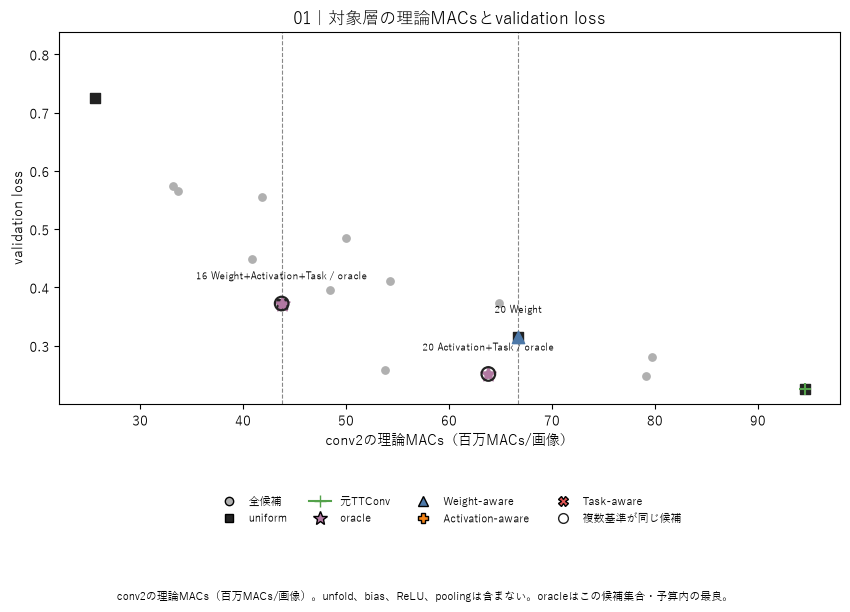

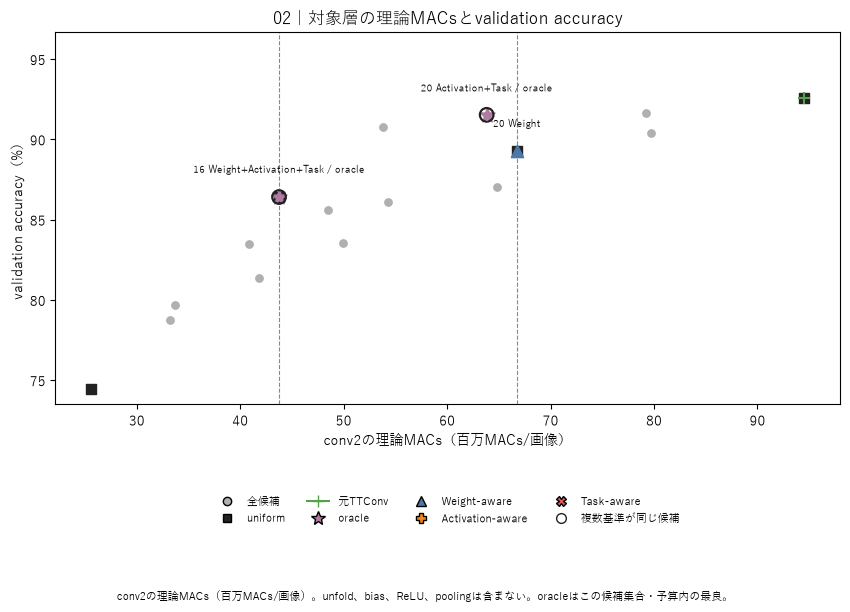

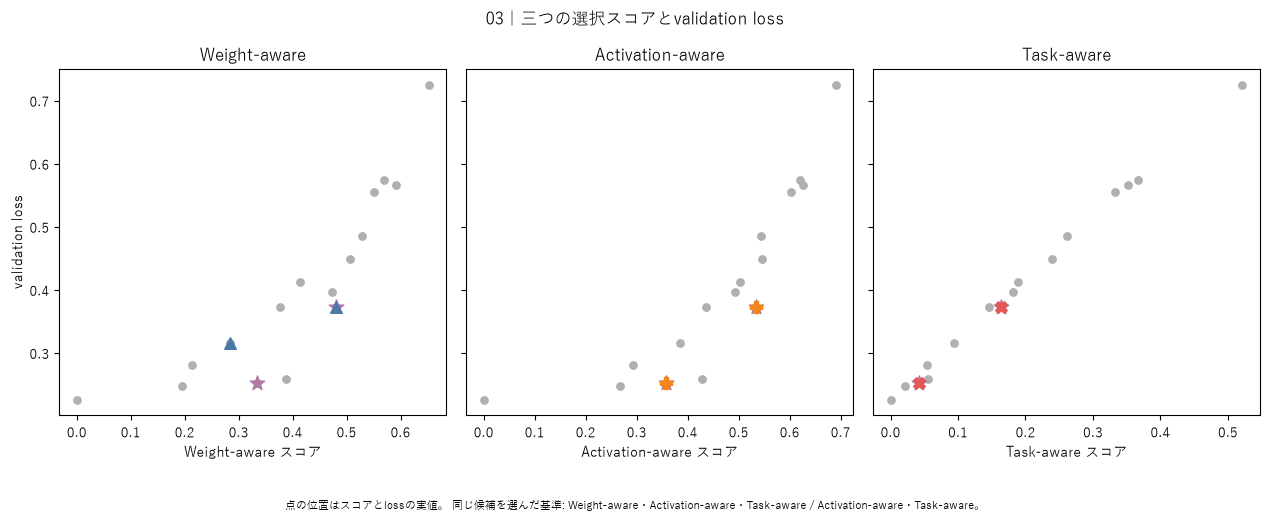

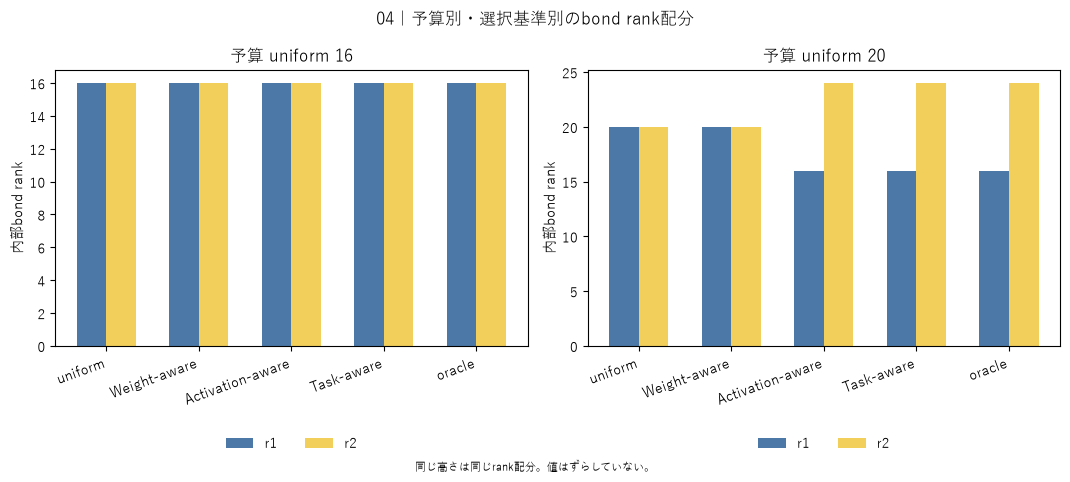

figures redrawn: D:\dev\nn-compression-svd-dmrg\results\40_dmrg\20_fashion_mnist_cnn\00_posthoc_nonuniform_ttconv_rank_allocation_criteria\figures


In [18]:
def load_candidate(payload, models_dir, ranks, device):
    path = candidate_model_dir(models_dir, ranks) / "model.pt"
    if not path.is_file():
        raise RuntimeError(f"候補モデルがmodels配下にありません: {path}")
    state = torch.load(path, map_location="cpu", weights_only=True)
    model = model_from_cores(payload, [state[f"conv2.cores.{index}"] for index in range(3)])
    model.load_state_dict(state)
    return model.to(device).eval()


def record_from_model(experiment_id, ranks, bond_order, canonicality, model, scores, source_loss, seconds):
    structure = structure_of(model)
    return {
        "experiment_id": experiment_id,
        "candidate_id": candidate_id(ranks),
        "ranks": rank_text(ranks),
        "actual_ranks": [int(rank) for rank in ranks],
        "r1": int(ranks[1]),
        "r2": int(ranks[2]),
        "bond_order": "|".join(str(bond) for bond in bond_order),
        "complete": True,
        "canonicality_max_error": canonicality,
        "tt_core_elements": structure["tt_core_elements"],
        "conv2_parameters": structure["conv2_parameters"],
        "total_parameters": structure["total_parameters"],
        "conv2_theoretical_macs": structure["conv2_theoretical_macs"],
        "model_theoretical_macs": structure["model_theoretical_macs"],
        "weight_score": scores["weight_score"],
        "activation_score": scores["activation_score"],
        "task_score": scores["task_score"],
        "calibration_loss": scores["calibration_loss"],
        "calibration_accuracy": scores["calibration_accuracy"],
        "baseline_calibration_loss": source_loss,
        "seconds": seconds,
    }


def ensure_calibration(payload, source_on_device, source_snapshot, source_cores, models_dir, results_dir, pairs, experiment, dataset, device, source_loss, source_weight):
    records = []
    completed = []
    write_run_state(
        results_dir,
        experiment_id=experiment,
        stage="calibration",
        completed_candidate_ids=[],
        completed_candidate_count=0,
        candidate_count=len(pairs),
        current_candidate_id="",
        selection_saved=False,
        validation_started=False,
    )
    for left, right in pairs:
        ranks = ranks_of(left, right)
        item_id = candidate_id(ranks)
        write_run_state(results_dir, stage="calibration", current_candidate_id=item_id)
        existing = completed_calibration(models_dir, results_dir, ranks, experiment)
        if existing is not None:
            records.append(existing)
            completed.append(item_id)
            write_run_state(
                results_dir,
                stage="calibration",
                current_candidate_id=item_id,
                completed_candidate_ids=list(completed),
                completed_candidate_count=len(completed),
            )
            continue
        started = time.perf_counter()
        cores, canonicality = truncate_from_source(source_cores, ranks, PRIMARY_BOND_ORDER)
        candidate = model_from_cores(payload, cores).to(device)
        outside_and_bias_unchanged(candidate, source_snapshot)
        if tuple(candidate.conv2.out_modes) != OUT_MODES or tuple(candidate.conv2.in_modes) != IN_MODES:
            raise RuntimeError("候補のtensorizationが変わりました。")
        scores = calibration_scores(source_on_device, candidate, dataset, device, source_loss, source_weight)
        record = record_from_model(
            experiment, ranks, PRIMARY_BOND_ORDER, canonicality, candidate, scores, source_loss,
            time.perf_counter() - started,
        )
        save_calibration(models_dir, results_dir, record, candidate.cpu())
        records.append(record)
        completed.append(item_id)
        write_run_state(
            results_dir,
            stage="calibration",
            current_candidate_id=item_id,
            completed_candidate_ids=list(completed),
            completed_candidate_count=len(completed),
        )
        del candidate
    if len({record["ranks"] for record in records}) != len(records):
        raise RuntimeError("actual rank列が候補間で重複しました。")
    return records


def source_metrics(source, device, dataset, rank_dataset, source_loss, source_accuracy):
    structure = structure_of(source)
    validation_loss, validation_accuracy = classification_metrics(source, rank_dataset, device)
    return {
        "experiment_id": None,
        "candidate_id": "source_checkpoint",
        "ranks": rank_text(structure["actual_ranks"]),
        "role": "source",
        "tt_core_elements": structure["tt_core_elements"],
        "conv2_parameters": structure["conv2_parameters"],
        "total_parameters": structure["total_parameters"],
        "conv2_theoretical_macs": structure["conv2_theoretical_macs"],
        "model_theoretical_macs": structure["model_theoretical_macs"],
        "weight_score": 0.0,
        "activation_score": 0.0,
        "task_score": 0.0,
        "calibration_loss": source_loss,
        "calibration_accuracy": source_accuracy,
        "validation_loss": validation_loss,
        "validation_accuracy": validation_accuracy,
    }


def ensure_validation(payload, models_dir, results_dir, pairs, experiment, rank_dataset, device):
    rows = []
    completed = []
    write_run_state(
        results_dir,
        stage="validation",
        validation_started=True,
        completed_candidate_ids=[],
        completed_candidate_count=0,
        candidate_count=len(pairs),
        current_candidate_id="",
    )
    for left, right in pairs:
        ranks = ranks_of(left, right)
        item_id = candidate_id(ranks)
        write_run_state(results_dir, stage="validation", validation_started=True, current_candidate_id=item_id)
        directory = candidate_results_dir(results_dir, ranks)
        path = directory / "validation.json"
        existing = require_same_experiment(path, experiment) if path.is_file() else None
        calibration = require_same_experiment(directory / "calibration.json", experiment)
        if calibration is None:
            raise RuntimeError("calibrationが無い候補のvalidationは始めません。")
        if existing is not None:
            rows.append({**calibration, **existing})
            completed.append(item_id)
            write_run_state(
                results_dir,
                stage="validation",
                validation_started=True,
                current_candidate_id=item_id,
                completed_candidate_ids=list(completed),
                completed_candidate_count=len(completed),
            )
            continue
        started = time.perf_counter()
        model = load_candidate(payload, models_dir, ranks, device)
        loss, accuracy = classification_metrics(model, rank_dataset, device)
        payload_validation = {
            "experiment_id": experiment,
            "candidate_id": item_id,
            "ranks": rank_text(ranks),
            "validation_loss": loss,
            "validation_accuracy": accuracy,
            "seconds": time.perf_counter() - started,
            "selection_already_saved": True,
        }
        atomic_write_json(path, payload_validation)
        rows.append({**calibration, **payload_validation})
        completed.append(item_id)
        write_run_state(
            results_dir,
            stage="validation",
            validation_started=True,
            current_candidate_id=item_id,
            completed_candidate_ids=list(completed),
            completed_candidate_count=len(completed),
        )
        del model
    return rows


def write_validation_outputs(results_dir, validation_records, selections, experiment_id):
    frame = pd.DataFrame(validation_records)
    if frame.empty or frame["candidate_id"].duplicated().any():
        raise RuntimeError("validation候補が空か、重複しています。")
    rows = []
    for selection in selections:
        if str(selection.get("validation_used", False)).strip().lower() == "true":
            raise RuntimeError("selectionがvalidationを使っています。候補は選び直しません。")
        uniform = int(selection["budget_rank"])
        budget = int(selection["budget_conv2_theoretical_macs"])
        feasible = frame[frame["conv2_theoretical_macs"] <= budget].sort_values(
            by=["validation_loss", "conv2_theoretical_macs", "total_parameters", "ranks"],
            kind="mergesort",
        )
        if feasible.empty or selection["candidate_id"] not in set(feasible["candidate_id"]):
            raise RuntimeError(f"予算 {uniform} の選択候補がvalidation済み候補にありません。選び直しません。")
        oracle = feasible.iloc[0]
        chosen = frame[frame["candidate_id"] == selection["candidate_id"]].iloc[0]
        uniform_row = frame[frame["ranks"] == rank_text(ranks_of(uniform, uniform))]
        if len(uniform_row) != 1:
            raise RuntimeError(f"uniform rank {uniform} のvalidationがありません。")
        uniform_row = uniform_row.iloc[0]
        rank_position = int(feasible["candidate_id"].tolist().index(selection["candidate_id"])) + 1
        rows.append({
            "experiment_id": experiment_id,
            "selection_criterion": selection["selection_criterion"],
            "budget_rank": uniform,
            "budget_conv2_theoretical_macs": budget,
            "candidate_id": selection["candidate_id"],
            "ranks": selection["ranks"],
            "validation_loss": float(chosen["validation_loss"]),
            "validation_accuracy": float(chosen["validation_accuracy"]),
            "oracle_candidate_id": oracle["candidate_id"],
            "oracle_ranks": oracle["ranks"],
            "oracle_validation_loss": float(oracle["validation_loss"]),
            "oracle_validation_accuracy": float(oracle["validation_accuracy"]),
            "oracle_regret": float(chosen["validation_loss"]) - float(oracle["validation_loss"]),
            "budget_validation_rank": rank_position,
            "uniform_ranks": uniform_row["ranks"],
            "uniform_validation_loss": float(uniform_row["validation_loss"]),
            "uniform_validation_accuracy": float(uniform_row["validation_accuracy"]),
            "loss_minus_uniform": float(chosen["validation_loss"]) - float(uniform_row["validation_loss"]),
            "accuracy_minus_uniform": float(chosen["validation_accuracy"]) - float(uniform_row["validation_accuracy"]),
            "macs_minus_uniform": int(chosen["conv2_theoretical_macs"]) - int(uniform_row["conv2_theoretical_macs"]),
            "oracle_scope": "fixed_candidate_set_and_budget",
            "oracle_is_selection_method": False,
            "selection_changed_by_validation": False,
        })
    atomic_write_csv(results_dir / "oracle_regret.csv", rows, list(rows[0]))
    return rows


def write_tables(results_dir, source_record, calibration_records, validation_records, selections):
    atomic_write_csv(results_dir / "calibration_metrics.csv", calibration_records, list(calibration_records[0]))
    atomic_write_csv(results_dir / "selection.csv", selections, list(selections[0]))
    atomic_write_csv(results_dir / "validation_metrics.csv", [
        {key: record[key] for key in (
            "experiment_id", "candidate_id", "ranks", "validation_loss", "validation_accuracy", "seconds",
        )}
        for record in validation_records
    ], ["experiment_id", "candidate_id", "ranks", "validation_loss", "validation_accuracy", "seconds"])
    regret_rows = write_validation_outputs(results_dir, validation_records, selections, source_record["experiment_id"])
    frame = pd.DataFrame(validation_records)
    rows = []
    for uniform in sorted({int(row["budget_rank"]) for row in regret_rows}):
        group = [row for row in regret_rows if int(row["budget_rank"]) == uniform]
        budget = int(group[0]["budget_conv2_theoretical_macs"])
        oracle_ids = {row["oracle_candidate_id"] for row in group}
        if len(oracle_ids) != 1:
            raise RuntimeError("同じ予算のoracleが一致しません。")
        oracle_loss = float(group[0]["oracle_validation_loss"])
        feasible = frame[frame["conv2_theoretical_macs"] <= budget].sort_values(
            by=["validation_loss", "conv2_theoretical_macs", "total_parameters", "ranks"],
            kind="mergesort",
        )
        ranking = {candidate: position + 1 for position, candidate in enumerate(feasible["candidate_id"].tolist())}

        def add_row(role, item):
            inside = role != "source" and item["candidate_id"] in ranking
            rows.append({
                "budget_rank": uniform,
                "role": role,
                "ranks": item["ranks"],
                "tt_core_elements": int(item["tt_core_elements"]),
                "conv2_parameters": int(item["conv2_parameters"]),
                "total_parameters": int(item["total_parameters"]),
                "conv2_theoretical_macs": int(item["conv2_theoretical_macs"]),
                "model_theoretical_macs": int(item["model_theoretical_macs"]),
                "weight_score": float(item["weight_score"]),
                "activation_score": float(item["activation_score"]),
                "task_score": float(item["task_score"]),
                "validation_loss": float(item["validation_loss"]),
                "validation_accuracy": float(item["validation_accuracy"]),
                "oracle_regret": float(item["validation_loss"]) - oracle_loss if inside else "",
                "budget_validation_rank": ranking[item["candidate_id"]] if inside else "",
                "inside_budget": inside,
            })

        add_row("source", source_record)
        add_row("uniform", frame[frame["ranks"] == rank_text(ranks_of(uniform, uniform))].iloc[0].to_dict())
        for criterion in CRITERIA:
            matched = [row for row in group if row["selection_criterion"] == criterion][0]
            add_row(criterion, frame[frame["candidate_id"] == matched["candidate_id"]].iloc[0].to_dict())
        add_row("oracle", frame[frame["candidate_id"] == group[0]["oracle_candidate_id"]].iloc[0].to_dict())
    atomic_write_csv(results_dir / "comparison.csv", rows, list(rows[0]))
    spearman_rows = []
    for column in ("weight_score", "activation_score", "task_score"):
        left = frame[column].rank(method="average")
        right = frame["validation_loss"].rank(method="average")
        spearman_rows.append({
            "experiment_id": source_record["experiment_id"],
            "score": column.removesuffix("_score"),
            "candidate_count": int(len(frame)),
            "spearman_with_validation_loss": float(left.corr(right)),
            "pvalue_reported": False,
        })
    atomic_write_csv(results_dir / "spearman.csv", spearman_rows, list(spearman_rows[0]))
    return regret_rows, rows


def save_figure(figure, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(path, dpi=150, bbox_inches="tight")
    display(figure)
    plt.close(figure)


def render_figures(results_dir, validation_records, source_record, regret_rows):
    frame = pd.DataFrame(validation_records).copy()
    figures = results_dir / "figures"
    colors = {"weight": "#4c78a8", "activation": "#f58518", "task": "#e45756"}
    markers = {"weight": "^", "activation": "P", "task": "X"}
    criterion_label = {
        "weight": "Weight-aware",
        "activation": "Activation-aware",
        "task": "Task-aware",
    }
    note = "conv2の理論MACs（百万MACs/画像）。unfold、bias、ReLU、poolingは含まない。oracleはこの候補集合・予算内の最良。"

    def million(value):
        return float(value) / 1_000_000.0

    def y_of(record, column):
        value = float(record[column])
        return value * 100.0 if column == "validation_accuracy" else value

    def lookup(candidate):
        matched = frame[frame["candidate_id"] == candidate]
        if len(matched) != 1:
            raise RuntimeError(f"図に使う候補が見つかりません: {candidate}")
        return matched.iloc[0]

    oracle_budgets = {}
    selected = {}
    for row in regret_rows:
        oracle_budgets.setdefault(row["oracle_candidate_id"], set()).add(int(row["budget_rank"]))
        selected.setdefault(row["candidate_id"], []).append(row)

    def draw_reference(axis, y_column):
        scale = 100.0 if y_column == "validation_accuracy" else 1.0
        axis.scatter(
            frame["conv2_theoretical_macs"].map(million), frame[y_column].astype(float) * scale,
            s=28, c="#b0b0b0", marker="o", zorder=1,
        )
        uniform = frame[frame["r1"] == frame["r2"]]
        uniform_y = uniform[y_column] * (100.0 if y_column == "validation_accuracy" else 1.0)
        axis.scatter(uniform["conv2_theoretical_macs"].map(million), uniform_y, s=46, c="#222222", marker="s", zorder=2)
        axis.scatter(
            [million(source_record["conv2_theoretical_macs"])],
            [y_of(source_record, y_column)],
            s=70, c="#54a24b", marker="+", zorder=3,
        )
        drawn_oracle = set()
        for candidate, budgets in oracle_budgets.items():
            if candidate in drawn_oracle:
                continue
            item = lookup(candidate)
            axis.scatter(
                [million(item["conv2_theoretical_macs"])], [y_of(item, y_column)],
                s=130, c="#b279a2", marker="*", zorder=4,
            )
            drawn_oracle.add(candidate)
        for candidate, rows in selected.items():
            item = lookup(candidate)
            criteria = []
            for row in rows:
                name = row["selection_criterion"]
                if name not in criteria:
                    criteria.append(name)
            if len(criteria) == 1:
                name = criteria[0]
                axis.scatter(
                    [million(item["conv2_theoretical_macs"])], [y_of(item, y_column)],
                    s=78, c=colors[name], marker=markers[name], zorder=5,
                )
            else:
                axis.scatter(
                    [million(item["conv2_theoretical_macs"])], [y_of(item, y_column)],
                    s=96, facecolors="none", edgecolors="#222222", marker="o", linewidths=1.6, zorder=6,
                )
            short_label = {"weight": "Weight", "activation": "Activation", "task": "Task"}
            parts = []
            for budget in sorted({int(row["budget_rank"]) for row in rows}):
                names = []
                for row in rows:
                    if int(row["budget_rank"]) == budget and row["selection_criterion"] not in names:
                        names.append(row["selection_criterion"])
                parts.append(f"{budget} " + "+".join(short_label[name] for name in names))
            if candidate in oracle_budgets:
                parts.append("oracle")
            axis.annotate(
                " / ".join(parts),
                (million(item["conv2_theoretical_macs"]), y_of(item, y_column)),
                textcoords="offset points", xytext=(0, 16), ha="center", va="bottom", fontsize=7, annotation_clip=False,
            )
        for candidate, budgets in oracle_budgets.items():
            if candidate in selected:
                continue
            item = lookup(candidate)
            axis.annotate(
                "oracle " + "+".join(str(budget) for budget in sorted(budgets)),
                (million(item["conv2_theoretical_macs"]), y_of(item, y_column)),
                textcoords="offset points", xytext=(0, 16), ha="center", va="bottom", fontsize=7, annotation_clip=False,
            )
        for budget in sorted({int(row["budget_conv2_theoretical_macs"]) for row in regret_rows}):
            axis.axvline(million(budget), color="#888888", linewidth=0.8, linestyle="--", zorder=0)

    def finish(figure, axis, title):
        axis.set_title(title)
        axis.set_xlabel("conv2の理論MACs（百万MACs/画像）")
        handles = [
            plt.Line2D([0], [0], marker="o", color="none", markerfacecolor="#b0b0b0", markersize=6, label="全候補"),
            plt.Line2D([0], [0], marker="s", color="none", markerfacecolor="#222222", markersize=6, label="uniform"),
            plt.Line2D([0], [0], marker="+", color="#54a24b", markerfacecolor="#54a24b", markersize=8, label="元TTConv"),
            plt.Line2D([0], [0], marker="*", color="none", markerfacecolor="#b279a2", markersize=10, label="oracle"),
        ]
        for name in CRITERIA:
            handles.append(plt.Line2D(
                [0], [0], marker=markers[name], color="none", markerfacecolor=colors[name], markersize=7,
                label=criterion_label[name],
            ))
        handles.append(plt.Line2D(
            [0], [0], marker="o", color="none", markerfacecolor="none", markeredgecolor="#222222",
            markersize=7, label="複数基準が同じ候補",
        ))
        low, high = axis.get_ylim()
        axis.set_ylim(low, high + (high - low) * 0.16)
        axis.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4, frameon=False, fontsize=8)
        figure.tight_layout()
        figure.subplots_adjust(bottom=0.34)
        figure.text(0.5, 0.02, note, ha="center", va="bottom", fontsize=8)

    figure, axis = plt.subplots(figsize=(8.6, 6.2))
    draw_reference(axis, "validation_loss")
    axis.set_ylabel("validation loss")
    finish(figure, axis, "01｜対象層の理論MACsとvalidation loss")
    save_figure(figure, figures / "01_conv2_macs_vs_validation_loss.png")

    figure, axis = plt.subplots(figsize=(8.6, 6.2))
    draw_reference(axis, "validation_accuracy")
    axis.set_ylabel("validation accuracy（%）")
    finish(figure, axis, "02｜対象層の理論MACsとvalidation accuracy")
    save_figure(figure, figures / "02_conv2_macs_vs_validation_accuracy.png")

    figure, axes = plt.subplots(1, 3, figsize=(12.8, 5.2), sharey=True)
    score_labels = {
        "weight_score": "Weight-aware スコア",
        "activation_score": "Activation-aware スコア",
        "task_score": "Task-aware スコア",
    }
    for axis, column, criterion in zip(axes, ("weight_score", "activation_score", "task_score"), CRITERIA):
        axis.scatter(frame[column], frame["validation_loss"], s=28, c="#b0b0b0", zorder=1)
        for candidate in oracle_budgets:
            item = lookup(candidate)
            axis.scatter([item[column]], [item["validation_loss"]], s=120, c="#b279a2", marker="*", zorder=3)
        for candidate, rows in selected.items():
            names = {row["selection_criterion"] for row in rows}
            if criterion not in names:
                continue
            item = lookup(candidate)
            axis.scatter([item[column]], [item["validation_loss"]], s=70, c=colors[criterion], marker=markers[criterion], zorder=4)
        axis.set_xlabel(score_labels[column])
        axis.set_title(criterion_label[criterion])
    axes[0].set_ylabel("validation loss")
    shared_labels = []
    for candidate, rows in selected.items():
        names = []
        for row in rows:
            label = criterion_label[row["selection_criterion"]]
            if label not in names:
                names.append(label)
        if len(names) > 1:
            shared_labels.append("・".join(names))
    caption = "点の位置はスコアとlossの実値。"
    if shared_labels:
        caption += " 同じ候補を選んだ基準: " + " / ".join(shared_labels) + "。"
    figure.suptitle("03｜三つの選択スコアとvalidation loss")
    figure.tight_layout()
    figure.subplots_adjust(bottom=0.20)
    figure.text(0.5, 0.02, caption, ha="center", fontsize=8)
    save_figure(figure, figures / "03_scores_vs_validation_loss.png")

    budgets = sorted({int(row["budget_rank"]) for row in regret_rows})
    figure, axes = plt.subplots(1, len(budgets), figsize=(5.4 * len(budgets), 4.8), squeeze=False)
    for axis, uniform in zip(axes[0], budgets):
        group = [row for row in regret_rows if int(row["budget_rank"]) == uniform]
        labels = ["uniform", *[criterion_label[name] for name in CRITERIA], "oracle"]
        ids = [candidate_id(ranks_of(uniform, uniform))]
        ids.extend(next(row["candidate_id"] for row in group if row["selection_criterion"] == name) for name in CRITERIA)
        ids.append(group[0]["oracle_candidate_id"])
        r1, r2 = [], []
        for item_id in ids:
            item = lookup(item_id)
            r1.append(int(item["r1"]))
            r2.append(int(item["r2"]))
        positions = list(range(len(labels)))
        axis.bar([item - 0.16 for item in positions], r1, width=0.32, label="r1", color="#4c78a8")
        axis.bar([item + 0.16 for item in positions], r2, width=0.32, label="r2", color="#f2cf5b")
        axis.set_xticks(positions, labels, rotation=20, ha="right")
        axis.set_ylabel("内部bond rank")
        axis.set_title(f"予算 uniform {uniform}")
        axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, frameon=False)
    figure.suptitle("04｜予算別・選択基準別のbond rank配分")
    figure.tight_layout()
    figure.subplots_adjust(bottom=0.28)
    figure.text(0.5, 0.02, "同じ高さは同じrank配分。値はずらしていない。", ha="center", fontsize=8)
    save_figure(figure, figures / "04_rank_allocation.png")


def reverse_control(payload, source_cores, source_weight, models_dir, results_dir, regret_rows, rank_dataset, device, experiment):
    seen = []
    rows = []
    for regret in regret_rows:
        ranks = tuple(int(part) for part in regret["ranks"].split("|"))
        if ranks in seen:
            continue
        seen.append(ranks)
        cores, _canonicality = truncate_from_source(source_cores, ranks, REVERSE_BOND_ORDER)
        candidate = model_from_cores(payload, cores).to(device)
        primary = load_candidate(payload, models_dir, ranks, device)
        weight_gap = require_finite(
            relative_frobenius_error(dense_conv2_weight(primary), dense_conv2_weight(candidate)).detach(),
            "reverse weight",
        )
        loss, accuracy = classification_metrics(candidate, rank_dataset, device)
        primary_loss = float(pd.read_csv(results_dir / "validation_metrics.csv").set_index("candidate_id").loc[candidate_id(ranks), "validation_loss"])
        rows.append({
            "experiment_id": experiment,
            "ranks": rank_text(ranks),
            "bond_order": "|".join(str(bond) for bond in REVERSE_BOND_ORDER),
            "weight_relative_frobenius_vs_primary": weight_gap,
            "validation_loss": loss,
            "validation_accuracy": accuracy,
            "validation_loss_minus_primary": loss - primary_loss,
            "selection_updated": False,
        })
        del candidate, primary
    atomic_write_csv(results_dir / "reverse_order_control.csv", rows, list(rows[0]))
    return rows


def report_mlp_connection(results_dir):
    print("CNNの内部bondは2本なので、配分は (r1, r2) の組である。Notebook 10のTT-MLPは内部bondが4本で、同じ基準名でも選ばれる列の形は同じではない。")
    if NOTEBOOK10_REGRET.is_file() and NOTEBOOK10_SPEARMAN.is_file():
        regret = pd.read_csv(NOTEBOOK10_REGRET)
        spearman = pd.read_csv(NOTEBOOK10_SPEARMAN)
        print("Notebook 10の保存済みregret:")
        print(regret.groupby(["model_type", "budget_role", "selection_criterion"])["loss_regret"].min().to_string())
        weight_rows = spearman[spearman["score"] == "weight"]
        print("Notebook 10のweight scoreとvalidation lossのSpearman:")
        print(weight_rows[["model_type", "scope", "spearman_with_validation_loss"]].to_string(index=False))
    else:
        print("Notebook 10の保存済み比較ファイルが見つからない。")
    comparison_path = results_dir / "comparison.csv"
    if comparison_path.is_file():
        comparison = pd.read_csv(comparison_path)
        print("今回の予算ごとの選択rank:")
        print(comparison[comparison["role"].isin(CRITERIA)][["budget_rank", "role", "ranks", "oracle_regret", "budget_validation_rank"]].to_string(index=False))
        print("Weight-awareの順位がvalidation loss順位と一致するかは、上のbudget_validation_rankが1かどうかで見る。一致しなくても失敗にはしない。")
    else:
        print("今回のCNN比較表はまだない。mainを実行すると、同じ基準が良かったか、同じ配分傾向か、Weight-awareと分類性能の順位が一致したかをこの表から読む。")


def run_experiment(mode):
    require_switches()
    started = time.perf_counter()
    payload, source_config = load_source_payload()
    assert_preregistered_budgets()
    source = build_model(payload)
    snapshot = snapshot_state(source)
    source_cores = [core.detach().cpu().clone() for core in source.conv2.cores]
    splits = load_splits()
    eval_device = "cuda" if torch.cuda.is_available() else "cpu"
    config = experiment_config(mode, splits, eval_device, payload, source_config)
    experiment = config["experiment_id"]
    models_dir, results_dir = output_dirs(mode)
    reject_legacy_candidate_models(results_dir)
    results_dir.mkdir(parents=True, exist_ok=True)
    models_dir.mkdir(parents=True, exist_ok=True)
    config_path = results_dir / "config.json"
    previous = require_saved_config(config_path, config)
    if previous is None:
        existing = [item for item in results_dir.rglob("*") if item.is_file()]
        existing.extend(item for item in models_dir.rglob("*") if item.is_file())
        if existing:
            raise RuntimeError("config.jsonがないまま既存ファイルがあります。上書きも削除もしません。")
        atomic_write_json(config_path, config)
    else:
        descriptive_keys = (
            "source_selection_criterion",
            "source_selected_epoch",
            "source_rank_role",
            "test_evaluated",
            "finetuning",
        )
        if any(previous.get(key) != config.get(key) for key in descriptive_keys):
            raise RuntimeError("保存済みconfigの元checkpoint記録が違います。上書きも削除もしません。")
    write_run_state(
        results_dir,
        experiment_id=experiment,
        mode=mode,
        stage="setup",
        completed_candidate_ids=[],
        completed_candidate_count=0,
        candidate_count=len(rank_pairs(mode)),
        current_candidate_id="",
        selection_saved=False,
        validation_started=False,
        reverse_control_done=False,
        reverse_control_status="pending",
        stop_reason="",
    )
    source_on_device = copy.deepcopy(source).to(eval_device)
    source_loss, source_accuracy = classification_metrics(source_on_device, splits["calibration"], eval_device)
    source_weight = dense_conv2_weight(source).detach().cpu()
    control_path = results_dir / "control_verification.json"
    if control_path.is_file():
        saved_control = require_same_experiment(control_path, experiment)
        if not saved_control.get("passed"):
            raise RuntimeError("保存済みの元rank controlが失敗しています。上書きしません。")
    control = verify_identity_control(
        source, payload, source_cores, snapshot, splits["calibration"], eval_device,
    )
    assert_same_state(source, snapshot)
    if not control["passed"]:
        if not control_path.is_file():
            atomic_write_json(control_path, {"experiment_id": experiment, **control})
        raise RuntimeError("元rank controlが失敗したため候補評価へ進みません。")
    if not control_path.is_file():
        atomic_write_json(control_path, {"experiment_id": experiment, **control})
    write_run_state(results_dir, experiment_id=experiment, mode=mode, stage="control", stop_reason="")
    pairs = rank_pairs(mode)
    selection_path = results_dir / "selection.csv"
    validation_root = results_dir / "candidates"
    validation_paths = list(validation_root.glob("*/validation.json")) if validation_root.exists() else []
    if not selection_path.exists() and validation_paths:
        raise RuntimeError("selectionより前にvalidationファイルがあります。上書きしません。")
    calibration_records = ensure_calibration(
        payload, source_on_device, snapshot, source_cores, models_dir, results_dir, pairs, experiment,
        splits["calibration"], eval_device, source_loss, source_weight.to(eval_device),
    )
    budgets = {uniform: layer_macs(ranks_of(uniform, uniform)) for uniform in budget_ranks(mode)}
    if selection_path.exists():
        previous_selection = pd.read_csv(selection_path)
        used_validation = previous_selection["validation_used"].map(lambda value: str(value).strip().lower() == "true")
        if set(previous_selection["experiment_id"].astype(str)) != {experiment} or bool(used_validation.any()):
            raise RuntimeError("保存済みselectionがこの実験のcalibration選択ではありません。上書きしません。")
        selections = previous_selection.to_dict("records")
    else:
        selections = select_records(calibration_records, budgets)
        atomic_write_csv(selection_path, selections, list(selections[0]))
    write_run_state(
        results_dir,
        experiment_id=experiment,
        mode=mode,
        stage="selection_complete",
        selection_saved=True,
        validation_started=False,
        current_candidate_id="",
        stop_reason="",
    )
    source_record = source_metrics(
        source_on_device, eval_device, splits["calibration"], splits["rank_dataset"],
        source_loss, source_accuracy,
    )
    source_record["experiment_id"] = experiment
    source_metrics_path = results_dir / "source_metrics.json"
    if source_metrics_path.is_file():
        require_same_experiment(source_metrics_path, experiment)
    atomic_write_json(source_metrics_path, json_ready(source_record))
    validation_records = ensure_validation(
        payload, models_dir, results_dir, pairs, experiment, splits["rank_dataset"], eval_device,
    )
    regret_rows, _comparison = write_tables(
        results_dir, source_record, calibration_records, validation_records, selections,
    )
    write_run_state(results_dir, experiment_id=experiment, mode=mode, stage="analysis", current_candidate_id="")
    if mode == "main":
        reverse_control(
            payload, source_cores, source_weight, models_dir, results_dir, regret_rows,
            splits["rank_dataset"], eval_device, experiment,
        )
        write_run_state(
            results_dir,
            experiment_id=experiment,
            mode=mode,
            stage="reverse_control",
            reverse_control_done=True,
            reverse_control_status="completed",
        )
    else:
        write_run_state(
            results_dir,
            experiment_id=experiment,
            mode=mode,
            stage="reverse_control",
            reverse_control_done=False,
            reverse_control_status="not_run_for_smoke",
        )
    render_figures(results_dir, validation_records, source_record, regret_rows)
    write_run_state(results_dir, experiment_id=experiment, mode=mode, stage="figures")
    summary = {
        "experiment_id": experiment,
        "mode": mode,
        "stage": "complete",
        "candidate_count": len(pairs),
        "test_evaluated": False,
        "finetuning": False,
        "seconds": time.perf_counter() - started,
    }
    atomic_write_json(results_dir / "summary.json", summary)
    pointer_path = models_dir / "source_pointer.json"
    pointer = {
        "experiment_id": experiment,
        "source_checkpoint": str(SOURCE_CHECKPOINT.resolve()),
        "copied_weights": False,
    }
    if pointer_path.is_file():
        saved_pointer = read_json(pointer_path)
        if saved_pointer.get("experiment_id") != experiment or saved_pointer.get("source_checkpoint") != pointer["source_checkpoint"]:
            raise RuntimeError("source_pointerが現在の実験と違います。上書きしません。")
    else:
        atomic_write_json(pointer_path, pointer)
    assert_same_state(source, snapshot)
    report_mlp_connection(results_dir)
    write_run_state(
        results_dir,
        experiment_id=experiment,
        mode=mode,
        stage="complete",
        stop_reason="completed",
        current_candidate_id="",
    )
    print("saved:", results_dir)


def display_artifact_config() -> dict:
    return {
        "source_checkpoint": str(SOURCE_CHECKPOINT.resolve()),
        "target_layer": TARGET_LAYER,
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "source_ranks": list(SOURCE_RANKS),
        "rank_choices": list(RANK_CHOICES),
        "rank_pairs": [list(pair) for pair in rank_pairs("main")],
        "primary_bond_order": list(PRIMARY_BOND_ORDER),
        "reverse_bond_order": list(REVERSE_BOND_ORDER),
        "split_direction": SPLIT_DIRECTION,
        "dtype": "float32",
        "truncation_device": TRUNCATION_DEVICE,
        "cost_metric": COST_METRIC,
        "budget_ranks": [int(rank) for rank in PRIMARY_BUDGET_RANKS],
        "budget_conv2_theoretical_macs": {
            str(int(rank)): int(PRE_REGISTERED_LAYER_MACS[int(rank)])
            for rank in PRIMARY_BUDGET_RANKS
        },
        "criteria_definition": CRITERIA_DEFINITION,
        "selection_tie_break": list(SELECTION_TIE_BREAK),
        "reconstruction_tolerance": RECONSTRUCTION_TOLERANCE,
        "canonicality_tolerance": CANONICALITY_TOLERANCE,
        "loss_recheck_atol": LOSS_RECHECK_ATOL,
        "test_evaluated": False,
        "finetuning": False,
    }


DISPLAY_ARTIFACT_KEYS = (
    "source_checkpoint",
    "target_layer",
    "out_modes",
    "in_modes",
    "source_ranks",
    "rank_choices",
    "rank_pairs",
    "primary_bond_order",
    "reverse_bond_order",
    "split_direction",
    "dtype",
    "truncation_device",
    "cost_metric",
    "budget_ranks",
    "budget_conv2_theoretical_macs",
    "criteria_definition",
    "selection_tie_break",
    "reconstruction_tolerance",
    "canonicality_tolerance",
    "loss_recheck_atol",
    "test_evaluated",
    "finetuning",
)


def require_display_artifact_config(saved):
    current = display_artifact_config()
    diffs = [key for key in DISPLAY_ARTIFACT_KEYS if saved.get(key) != current[key]]
    if diffs:
        raise RuntimeError(
            "保存済みconfigと現在の表示対象条件が違います。"
            f"違い: {'、'.join(diffs)}。"
            "図は作らず、保存済みの図、config、CSVは変更しません。"
        )


def redraw_saved_figures():
    require_switches()
    _models_dir, results_dir = output_dirs("main")
    config_path = results_dir / "config.json"
    if not config_path.is_file():
        raise RuntimeError("mainの保存済みconfigがないため、図は描きません。")
    config = read_json(config_path)
    require_display_artifact_config(config)
    experiment = str(config.get("experiment_id", ""))
    if not experiment:
        raise RuntimeError("保存済みconfigに実験IDがありません。図は描きません。")
    required = {
        "calibration_metrics.csv": [
            "experiment_id", "candidate_id", "ranks", "r1", "r2", "conv2_theoretical_macs",
            "weight_score", "activation_score", "task_score",
        ],
        "validation_metrics.csv": ["experiment_id", "candidate_id", "ranks", "validation_loss", "validation_accuracy"],
        "selection.csv": ["experiment_id", "candidate_id", "selection_criterion", "budget_rank", "validation_used"],
        "oracle_regret.csv": [
            "experiment_id", "candidate_id", "selection_criterion", "budget_rank",
            "budget_conv2_theoretical_macs", "oracle_candidate_id", "oracle_validation_loss",
        ],
    }
    frames = {}
    for name, columns in required.items():
        file_path = results_dir / name
        if not file_path.is_file():
            raise RuntimeError(f"図の再生成に必要な保存がありません: {file_path}")
        frame = pd.read_csv(file_path)
        missing = [column for column in columns if column not in frame.columns]
        if missing:
            raise RuntimeError(f"{name} に必要な列がありません: {missing}")
        if set(frame["experiment_id"].astype(str)) != {experiment}:
            raise RuntimeError(f"{name} の実験IDがconfigと違います。図は描きません。")
        frames[name] = frame
    source = read_json(results_dir / "source_metrics.json")
    if str(source.get("experiment_id")) != experiment:
        raise RuntimeError("source_metricsの実験IDがconfigと違います。図は描きません。")
    calibration = frames["calibration_metrics.csv"]
    validation = frames["validation_metrics.csv"]
    if set(calibration["candidate_id"]) != set(validation["candidate_id"]):
        raise RuntimeError("calibrationとvalidationの候補IDが一致しません。")
    merged = calibration.merge(validation, on=["experiment_id", "candidate_id", "ranks"], how="inner")
    if len(merged) != len(calibration) or len(merged) != len(validation):
        raise RuntimeError("calibrationとvalidationの結合件数が一致しません。")
    known = set(calibration["candidate_id"])
    regret = frames["oracle_regret.csv"]
    if not set(regret["candidate_id"]).issubset(known) or not set(regret["oracle_candidate_id"]).issubset(known):
        raise RuntimeError("regretの候補IDが保存済み候補にありません。")
    if not set(frames["selection.csv"]["candidate_id"]).issubset(known):
        raise RuntimeError("selectionの候補IDが保存済み候補にありません。")
    before = config_path.read_bytes()
    render_figures(results_dir, merged.to_dict("records"), source, regret.to_dict("records"))
    if config_path.read_bytes() != before:
        raise RuntimeError("再描画がconfigを書き換えました。")
    print("figures redrawn:", results_dir / "figures")


def main():
    require_switches()
    if not (RUN_SMOKE or RUN_MAIN_EXPERIMENT or REGENERATE_DISPLAY_ARTIFACTS):
        print("実行スイッチはすべて False です。学習、候補評価、図の再生成は行いません。")
        return
    if REGENERATE_DISPLAY_ARTIFACTS and not RUN_SMOKE and not RUN_MAIN_EXPERIMENT:
        redraw_saved_figures()
        return
    if RUN_SMOKE:
        run_experiment("smoke")
        return
    if RUN_MAIN_EXPERIMENT:
        run_experiment("main")
        return
    raise RuntimeError("実行スイッチの組み合わせを解釈できません。")


main()
